# From Combine Speed to NFL Movement: What Tracking Reveals About Receiver Separation
### NFL Big Data Bowl 2027: public reproducibility notebook

This notebook accompanies the writeup. It does four things:

1. **Validates the competition data** (files, keys, season types, registered exclusions).
2. **Re-runs the frozen feature definitions:**
   - Combine tracked 40 peak speed;
   - game play-maximum speed;
   - task contexts;
   - the registered eligibility rules.
   It checks that it reproduces the registered sample sizes exactly.
3. **Explains the registered models** and **shows the registered results** with their run IDs, code commits and seeds.
4. **Draws every figure in the writeup** from those registered results.

**What this notebook deliberately does *not* do:**
- It does not re-fit any confirmatory model. The registered analysis runners (H1-WR, H2, secondary family) are one-shot by design: each refuses a second run, so that results cannot be re-drawn until they look better. Their outputs are embedded below, read-only.
- Combine values are never joined to game outcomes in this notebook. The sample-size reconstruction uses only *whether* a player has a valid tracked 40.
- No new association, subgroup or model is computed.
- No credentials are read, and no competition data is written anywhere except the notebook's temporary work directory.

| layer | variable used |
|---|---|
| **Capacity** (Combine) | tracked 40 peak speed, yd/s |
| **Game movement** | max speed on each REG play (WR/TE: before the throw), yd/s |
| **Football performance** | separation at the throw (yd), WR deep routes |
| **Deployment** | route, coverage, alignment, body weight |

## 0. Setup: locate the competition data, the pipeline code and a scratch work directory

In [1]:
import json, os, sys, time, tempfile, platform
from pathlib import Path
import numpy as np, polars as pl
import matplotlib, matplotlib.pyplot as plt
pl.Config.set_tbl_rows(30); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(180)

IS_KAGGLE = Path('/kaggle/input').exists()

def find_data_dir():
    cands = [os.environ.get('NFL_BDB_DATA'), '/kaggle/input/nfl-big-data-bowl-2027',
             '/kaggle/input/competitions/nfl-big-data-bowl-2027']
    here = Path.cwd()
    cands += [str(p / 'data/raw/nfl-big-data-bowl-2027') for p in (here, here.parent)]
    for c in cands:
        if c and (Path(c) / 'combine_results.csv').exists():
            return Path(c)
    raise FileNotFoundError('competition CSVs not found: attach the nfl-big-data-bowl-2027 competition data')

def find_code_dir():
    cands = [os.environ.get('NFL_BDB_CODE')]
    if IS_KAGGLE:   # the pipeline code is attached as a small Kaggle dataset (src/ + scripts/; no data)
        cands += [str(p.parent.parent) for p in Path('/kaggle/input').glob('*/src/nfl_bdb/__init__.py')]
        cands += [str(p.parent.parent) for p in Path('/kaggle/input').glob('*/*/src/nfl_bdb/__init__.py')]
    here = Path.cwd()
    cands += [str(here), str(here.parent)]
    for c in cands:
        if c and (Path(c) / 'src/nfl_bdb/__init__.py').exists():
            return Path(c)
    raise FileNotFoundError('pipeline code not found: attach the nfl-bdb-2027 pipeline-code dataset')

DATA = find_data_dir(); CODE = find_code_dir()
WORK = Path(os.environ.get('NFL_BDB_WORK') or ('/kaggle/working/nfl_bdb_work' if IS_KAGGLE else tempfile.mkdtemp(prefix='nfl_bdb_work_')))
WORK.mkdir(parents=True, exist_ok=True)
# safety: never write into the repository's registered data directory
assert 'data/interim' not in str(WORK.resolve()), 'work directory must not be the registered data/interim'
sys.path[:0] = [str(CODE / 'src'), str(CODE / 'scripts')]
_v = tuple(int(x) for x in pl.__version__.split('.')[:2])
assert _v >= (1, 0), f'polars >= 1.0 required (found {pl.__version__}); run: pip install -U polars'
print('Kaggle:', IS_KAGGLE, '| python', platform.python_version(), '| polars', pl.__version__, '| matplotlib', matplotlib.__version__)
print('data :', DATA); print('code :', CODE); print('work :', WORK)

# Run switches. Combine features take a few minutes; the game pipeline reads ~2 GB of tracking (~10-20 min).
RUN_COMBINE_FEATURES = True
RUN_GAME_PIPELINE = os.environ.get('NFL_BDB_SKIP_GAME', '0') != '1'

Kaggle: False | python 3.13.18 | polars 2.1.0 | matplotlib 3.11.2
data : /home/user/NFL-Big-Data-Bowl-2027/data/raw/nfl-big-data-bowl-2027
code : /home/user/NFL-Big-Data-Bowl-2027
work : /tmp/claude-0/-home-user-NFL-Big-Data-Bowl-2027/b6722030-edd8-51e4-893f-e33b48a07747/scratchpad/nb11_run/work2


In [2]:
# Point the frozen I/O module at the competition files and the scratch work directory BEFORE importing anything
# that caches paths. The frozen code itself is not modified (its hashes are checked in section 2).
from nfl_bdb.data import io as nio
nio.RAW, nio.INTERIM = DATA, WORK
from nfl_bdb.data import play_table as pt
pt.FEATURES = WORK / 'phase3_play_features.parquet'
from nfl_bdb.data import confirmatory_data as cd
import run_phase3_screening as p3
p3.INTERIM, p3.FEAT, p3.MATCH = WORK, WORK / 'phase3_play_features.parquet', WORK / 'phase3_matchups.parquet'
from run_real_capacity import forty_fits
from nfl_bdb.visualization import submission_figures as sf
assert nio.raw_path('players') == DATA / 'players.csv' and pt.FEATURES.parent == WORK
print('frozen pipeline imported; reading from', nio.RAW, 'writing to', nio.INTERIM)

frozen pipeline imported; reading from /home/user/NFL-Big-Data-Bowl-2027/data/raw/nfl-big-data-bowl-2027 writing to /tmp/claude-0/-home-user-NFL-Big-Data-Bowl-2027/b6722030-edd8-51e4-893f-e33b48a07747/scratchpad/nb11_run/work2


## 1. Registered results (read-only, embedded)

These numbers were produced once by the registered runners. They are embedded verbatim from `paper/registered_results.json`, which was built from the run outputs by `scripts/build_registered_results.py`. Each block names its source run file.

In [3]:
REGISTERED = json.loads(r'''{
 "_about": "Registered results for the NFL Big Data Bowl 2027 writeup. Aggregates only. Every block names its source run file. Built by scripts/build_registered_results.py.",
 "_sources": {
  "h1_wr": "experiments/h1_wr_confirmatory/20261121T223645Z/h1_wr_result.json",
  "h1_wr_robustness": "experiments/h1_wr_robustness/20261121T233918Z/robustness.json",
  "h2": "experiments/h2_estimation/20261122T012339Z/h2_result.json",
  "secondary": "experiments/secondary/20261122T015315Z/secondary_result.json",
  "dl_audit": "experiments/secondary/20261122T015315Z/dl_role_weight_diagnostics.json",
  "join": "experiments/confirmatory_join/20261121T135032Z/join_validation.json",
  "forty_reliability": "experiments/forty_reliability/20261121T134306Z/reliability.parquet",
  "phase3": "experiments/phase3_screening/20261121T010253Z"
 },
 "samples": {
  "source": "confirmatory_join/20261121T135032Z/join_validation.json",
  "join_run": "20261121T135032Z",
  "code_commit": "955d94d4486175223d045af6a883e09ac519432d",
  "matching_by_position": [
   {
    "pos": "DB",
    "combine_participants": 122,
    "valid_tracked_40": 102,
    "official_40": 104,
    "any_game_rows": 118,
    "REG_game_rows": 96,
    "matched_REG_and_valid_40": 81,
    "unmatched_no_REG_rows": 26,
    "REG_rows_but_no_valid_40": 15
   },
   {
    "pos": "DL",
    "combine_participants": 118,
    "valid_tracked_40": 93,
    "official_40": 94,
    "any_game_rows": 115,
    "REG_game_rows": 98,
    "matched_REG_and_valid_40": 77,
    "unmatched_no_REG_rows": 20,
    "REG_rows_but_no_valid_40": 21
   },
   {
    "pos": "OL",
    "combine_participants": 121,
    "valid_tracked_40": 95,
    "official_40": 95,
    "any_game_rows": 120,
    "REG_game_rows": 91,
    "matched_REG_and_valid_40": 73,
    "unmatched_no_REG_rows": 30,
    "REG_rows_but_no_valid_40": 18
   },
   {
    "pos": "TE",
    "combine_participants": 42,
    "valid_tracked_40": 34,
    "official_40": 34,
    "any_game_rows": 38,
    "REG_game_rows": 33,
    "matched_REG_and_valid_40": 28,
    "unmatched_no_REG_rows": 9,
    "REG_rows_but_no_valid_40": 5
   },
   {
    "pos": "WR",
    "combine_participants": 107,
    "valid_tracked_40": 94,
    "official_40": 97,
    "any_game_rows": 106,
    "REG_game_rows": 83,
    "matched_REG_and_valid_40": 73,
    "unmatched_no_REG_rows": 24,
    "REG_rows_but_no_valid_40": 10
   }
  ],
  "analysis": {
   "H1-WR": {
    "players": 57,
    "plays": 19960,
    "deep_plays": 9961,
    "short_plays": 9999
   },
   "H2-WR": {
    "players": 57,
    "deep_plays": 9935,
    "short_plays": 10032
   },
   "H1-DB": {
    "players": 52,
    "plays": 16643
   },
   "H1-DL": {
    "players": 53,
    "plays": 34154
   },
   "H1-OL": {
    "players": 53,
    "plays": 64285
   },
   "H1-TE": {
    "players": 17,
    "plays": 4170
   }
  }
 },
 "h1_wr": {
  "source": "h1_wr_confirmatory/20261121T223645Z/h1_wr_result.json",
  "run": "20261121T223645Z",
  "code_commit": "8674e8038a3f32b7ee3ff56ee7c3742915cca3f0",
  "seed": 4004,
  "B": 2000,
  "decision": "INCONCLUSIVE",
  "delta": 0.08995387496599844,
  "rho_deep": 0.5759012164461805,
  "rho_short": 0.4859473414801821,
  "ci95": [
   -0.08864589865155564,
   0.40005788730941566
  ],
  "ci90": [
   -0.04520594044979113,
   0.33303141992910895
  ],
  "se_boot": 0.12249346789396932,
  "p": 0.211,
  "season_forward_delta_2025": 0.21903877251676285,
  "sesoi": 0.15
 },
 "rho_by_context": {
  "source": "secondary/20261122T015315Z/secondary_result.json :: wald",
  "interval": "Wald 95 % (rho +/- 1.96 SE), clipped to [-1, 1]",
  "rows": [
   {
    "pos": "WR",
    "ctx": "deep",
    "rho": 0.5759012164461805,
    "se": 0.09633690276162454,
    "ci95_wald": [
     0.38708088703339644,
     0.7647215458589647
    ],
    "players": 57
   },
   {
    "pos": "WR",
    "ctx": "short",
    "rho": 0.4859473414801821,
    "se": 0.11238935856751625,
    "ci95_wald": [
     0.26566419868785024,
     0.706230484272514
    ],
    "players": 57
   },
   {
    "pos": "TE",
    "ctx": "deep",
    "rho": 0.29646833503383685,
    "se": 0.2742126586210835,
    "ci95_wald": [
     -0.24098847586348682,
     0.8339251459311605
    ],
    "players": 17
   },
   {
    "pos": "TE",
    "ctx": "short",
    "rho": 0.21344156618863902,
    "se": 0.2614766880856932,
    "ci95_wald": [
     -0.2990527424593196,
     0.7259358748365976
    ],
    "players": 17
   },
   {
    "pos": "DB",
    "ctx": "man",
    "rho": 0.29334872525163475,
    "se": 0.1719167750449974,
    "ci95_wald": [
     -0.04360815383656014,
     0.6303056043398296
    ],
    "players": 52
   },
   {
    "pos": "DB",
    "ctx": "deep_zone",
    "rho": 0.09115907269073352,
    "se": 0.17583906301940994,
    "ci95_wald": [
     -0.2534854908273099,
     0.435803636208777
    ],
    "players": 52
   },
   {
    "pos": "DB",
    "ctx": "under_zone",
    "rho": 0.14555114518489298,
    "se": 0.19321712769079596,
    "ci95_wald": [
     -0.23315442508906709,
     0.5242567154588531
    ],
    "players": 52
   },
   {
    "pos": "DL",
    "ctx": "pass_rush",
    "rho": 0.5681446383768897,
    "se": 0.09674087553088642,
    "ci95_wald": [
     0.37853252233635226,
     0.7577567544174271
    ],
    "players": 53
   },
   {
    "pos": "DL",
    "ctx": "run",
    "rho": 0.5301290224432772,
    "se": 0.11164437893175881,
    "ci95_wald": [
     0.31130603973702997,
     0.7489520051495244
    ],
    "players": 53
   },
   {
    "pos": "OL",
    "ctx": "pass_block",
    "rho": 0.10841214097978893,
    "se": 0.15108338571918412,
    "ci95_wald": [
     -0.1877112950298119,
     0.4045355769893898
    ],
    "players": 53
   },
   {
    "pos": "OL",
    "ctx": "run",
    "rho": 0.02499671139555694,
    "se": 0.15637036528063686,
    "ci95_wald": [
     -0.28148920455449133,
     0.3314826273456052
    ],
    "players": 53
   }
  ]
 },
 "contrasts": {
  "source": "secondary/20261122T015315Z/secondary_result.json :: family / tests / h5a",
  "H1-WR": {
   "estimate": 0.08995387496599844,
   "ci95": [
    -0.08864589865155564,
    0.40005788730941566
   ],
   "decision": "INCONCLUSIVE",
   "family": "primary"
  },
  "H1-DB": {
   "estimate": 0.13944879416372075,
   "ci95": [
    -0.6092481149798019,
    1.0500470005868368
   ],
   "p_unadjusted": 0.691,
   "p_holm": 1.0,
   "decision": "INCONCLUSIVE",
   "family": "Holm secondary"
  },
  "H1-DL(a)": {
   "estimate": 0.03801561593361247,
   "ci95": [
    -0.22871848525443514,
    0.15396707562281406
   ],
   "ci90": [
    -0.19048002468766442,
    0.1235680335103301
   ],
   "p_unadjusted": 0.931,
   "p_holm": 1.0,
   "decision": "FALSIFIED",
   "family": "Holm secondary"
  },
  "H1-DL(b)": {
   "estimate": 0.8158289301366086,
   "ci95": [
    0.16024289223277496,
    1.5375628856864894
   ],
   "p_unadjusted": 0.008,
   "p_holm": 0.032,
   "decision": "SUPPORTED",
   "family": "Holm secondary"
  },
  "H5(b)": {
   "estimate": 0.006455093308879625,
   "ci95": [
    -0.5728549990247107,
    0.6274373336215135
   ],
   "p_unadjusted": 0.833,
   "p_holm": 1.0,
   "decision": "INCONCLUSIVE",
   "family": "Holm secondary"
  },
  "H5(a) OL": {
   "estimate": 0.08349878165711881,
   "ci95": [
    -0.4572778546022564,
    0.6355806838441532
   ],
   "decision": "UNINFORMATIVE (estimation)",
   "family": "estimation"
  }
 },
 "h2": {
  "source": "h2_estimation/20261122T012339Z/h2_result.json",
  "code_commit": "e6e1ad4b07d99e980f65a51a1f7290a09a8b1708",
  "B": 2000,
  "status": "secondary, estimation-focused (D4, before any association)",
  "label": "INCONCLUSIVE",
  "beta_P_yd_per_sd": -0.019952328795119424,
  "beta_P_ci95_yd": [
   -0.10120485623456113,
   0.06321423644509064
  ],
  "beta_P_ci90_yd": [
   -0.08429707704203215,
   0.04863084884946322
  ],
  "beta_P_in_per_sd": -0.7182838366242993,
  "beta_P_ci95_in": [
   -3.6433748244442006,
   2.275712512023263
  ],
  "short_beta_P_yd": 0.1526263072784797,
  "short_beta_P_ci95_yd": [
   -0.10904737302949385,
   0.3653026542606941
  ],
  "short_beta_P_in": 5.494547062025269,
  "short_beta_P_ci95_in": [
   -3.9257054290617788,
   13.150895553384988
  ],
  "contrast_N3": {
   "estimate": -0.17257863607359913,
   "ci95": [
    -0.39166958349276415,
    0.0875421269418662
   ],
   "ci90": [
    -0.3537181888002259,
    0.05174012687050967
   ],
   "se": 0.12359269010858508
  },
  "partial_observed": -0.08111794337340741,
  "cv_frozen": {
   "r2_m1": -0.019876571675356492,
   "r2_m2": -0.04369978770410939,
   "dr2": -0.023823216028752904,
   "lb90": -0.03591053629355426,
   "boot_mean": -0.011840963075984355,
   "boot_sd": 0.020955462410615956
  },
  "season_forward": {
   "n": 30,
   "n_train_players": 40,
   "RMSE_M1": 0.13828414124601993,
   "RMSE_M2": 0.13799096200107344,
   "dRMSE": -0.0002931792449464843,
   "spearman_M1": 0.09221523792642285,
   "spearman_M2": 0.10122358175750834
  },
  "reliability_deep_level": 0.44254530921171836,
  "between_player_sd_yd": 0.1288495065524881,
  "eiv_tipping_RF": {
   "0.94": 0.7699623294326123,
   "0.987": 0.7332974566046999
  },
  "p_boot_reml": 0.708
 },
 "dl_b": {
  "source": "secondary/20261122T015315Z/dl_role_weight_diagnostics.json + secondary/20261122T015315Z/secondary_result.json :: dl_b",
  "registered": {
   "estimate": 0.8158289301366086,
   "ci95": [
    0.16024289223277496,
    1.5375628856864894
   ],
   "p_unadjusted": 0.008,
   "p_holm": 0.032,
   "decision": "SUPPORTED"
  },
  "base_pooled": 0.5491368304100834,
  "adjusted_pooled": -0.26669209972652524,
  "variants": [
   {
    "label": "unadjusted (registered model)",
    "pooled": 0.5491368304100834,
    "pooled_se": 0.09861727968784251,
    "ci95_wald": [
     0.35584696222191214,
     0.7424266985982547
    ]
   },
   {
    "label": "+ role x context",
    "pooled": -0.05228884216488872,
    "pooled_se": 0.21896655233765053,
    "ci95_wald": [
     -0.48146328474668376,
     0.37688560041690633
    ]
   },
   {
    "label": "+ weight x context",
    "pooled": -0.07915948966715634,
    "pooled_se": 0.24060306697976513,
    "ci95_wald": [
     -0.550741500947496,
     0.3924225216131833
    ]
   },
   {
    "label": "+ role and weight x context (registered adjusted)",
    "pooled": -0.26669209972652524,
    "pooled_se": 0.22698131771119553,
    "ci95_wald": [
     -0.7115754824404685,
     0.178191282987418
    ]
   }
  ],
  "within_role": {
   "EDGE": {
    "pooled": 0.04555845837018701,
    "pooled_se": 0.23433643315232003,
    "ci95_wald": [
     -0.41374095060836025,
     0.5048578673487343
    ]
   },
   "INTERIOR_LINE": {
    "pooled": 0.006634246674717712,
    "pooled_se": 0.20581470192160736,
    "ci95_wald": [
     -0.3967625690916327,
     0.4100310624410682
    ]
   }
  },
  "role_means": [
   {
    "modal": "EDGE",
    "n": 25,
    "x_peak": 10.5700831048,
    "x_sd": 0.33010778743784336,
    "combine_weight": 257.56,
    "w_sd": 11.090837058881833
   },
   {
    "modal": "INTERIOR_LINE",
    "n": 28,
    "x_peak": 9.708371321178571,
    "x_sd": 0.4869853684568257,
    "combine_weight": 304.2142857142857,
    "w_sd": 19.900413438580998
   }
  ],
  "corr_eligible": {
   "vars": [
    "x_peak",
    "combine_weight",
    "edge"
   ],
   "matrix": [
    [
     0.9999999999999998,
     -0.8022538506749899,
     0.7217676290393087
    ],
    [
     -0.80225385067499,
     1.0,
     -0.8234874863145714
    ],
    [
     0.7217676290393088,
     -0.8234874863145712,
     1.0
    ]
   ],
   "n": 53
  },
  "interval_note": "Variant intervals are Wald (descriptive audit); only the registered pooled-minus-adjusted test is inferential."
 },
 "combine_measurement": {
  "source": "forty_reliability/20261121T134306Z/reliability.parquet ; phase3_screening/20261121T010253Z/predictor_structure.parquet",
  "reliability": [
   {
    "pos": "ALL",
    "n": 371,
    "icc_single": 0.9866921155323495,
    "icc_single_ci95": [
     0.9838645871556918,
     0.9890212197024227
    ],
    "best_of_2": 0.9933014862425803
   },
   {
    "pos": "WR",
    "n": 82,
    "icc_single": 0.8888651224571412,
    "icc_single_ci95": [
     0.8208098688346873,
     0.9362218356605607
    ],
    "best_of_2": 0.9411631480609434
   },
   {
    "pos": "TE",
    "n": 32,
    "icc_single": 0.9281581245774658,
    "icc_single_ci95": [
     0.8514240810346588,
     0.9691167348937858
    ],
    "best_of_2": 0.9627406722992298
   },
   {
    "pos": "DB",
    "n": 90,
    "icc_single": 0.9264618860582545,
    "icc_single_ci95": [
     0.8903595402884372,
     0.9512017577375393
    ],
    "best_of_2": 0.961827371476208
   },
   {
    "pos": "DL",
    "n": 84,
    "icc_single": 0.975678027514829,
    "icc_single_ci95": [
     0.9619193242586411,
     0.9851430267643956
    ],
    "best_of_2": 0.9876893035472156
   },
   {
    "pos": "OL",
    "n": 83,
    "icc_single": 0.9327547166028959,
    "icc_single_ci95": [
     0.9019677761930844,
     0.9528513702116271
    ],
    "best_of_2": 0.9652075440202275
   }
  ],
  "vs_forty": [
   {
    "pos": "WR",
    "n": 94,
    "pearson": -0.8139579082334882,
    "unique_var": 0.33747252362416436
   },
   {
    "pos": "TE",
    "n": 34,
    "pearson": -0.910537848941288,
    "unique_var": 0.17092082564537225
   },
   {
    "pos": "OL",
    "n": 95,
    "pearson": -0.8986263167464599,
    "unique_var": 0.1924707428506912
   },
   {
    "pos": "DL",
    "n": 93,
    "pearson": -0.975149979497146,
    "unique_var": 0.04908251748671577
   },
   {
    "pos": "DB",
    "n": 102,
    "pearson": -0.7969013700576446,
    "unique_var": 0.36494820640024894
   }
  ],
  "vs_ten_yd_split": [
   {
    "pos": "WR",
    "n": 94,
    "spearman": -0.32588714947309677
   },
   {
    "pos": "TE",
    "n": 34,
    "spearman": -0.564104303983797
   },
   {
    "pos": "OL",
    "n": 95,
    "spearman": -0.5672750523093918
   },
   {
    "pos": "DL",
    "n": 93,
    "spearman": -0.8666868011010493
   },
   {
    "pos": "DB",
    "n": 102,
    "spearman": -0.47214990573633697
   }
  ],
  "vs_weight": [
   {
    "pos": "WR",
    "n": 94,
    "spearman": -0.26494061208241415
   },
   {
    "pos": "TE",
    "n": 34,
    "spearman": -0.05544934062562631
   },
   {
    "pos": "OL",
    "n": 95,
    "spearman": -0.062127299256888084
   },
   {
    "pos": "DL",
    "n": 93,
    "spearman": -0.7989113889105669
   },
   {
    "pos": "DB",
    "n": 102,
    "spearman": -0.22434087831105826
   }
  ]
 },
 "speed_demand": {
  "source": "phase3_screening/20261121T010253Z/speed_demand.parquet",
  "definition": "share of a position-context's plays whose max speed is >= 90 % of the player's own top-5 mean",
  "rows": [
   {
    "context": "deep",
    "plays": 13484,
    "median_play_vmax": 7.92,
    "share_plays_ge90pct_own_top": 0.16857015722337584,
    "pos": "WR"
   },
   {
    "context": "other",
    "plays": 4469,
    "median_play_vmax": 7.93,
    "share_plays_ge90pct_own_top": 0.13269187737748936,
    "pos": "WR"
   },
   {
    "context": "short",
    "plays": 17375,
    "median_play_vmax": 6.49,
    "share_plays_ge90pct_own_top": 0.008,
    "pos": "WR"
   },
   {
    "context": "short",
    "plays": 4649,
    "median_play_vmax": 5.91,
    "share_plays_ge90pct_own_top": 0.024736502473650248,
    "pos": "TE"
   },
   {
    "context": "other",
    "plays": 982,
    "median_play_vmax": 7.19,
    "share_plays_ge90pct_own_top": 0.1924643584521385,
    "pos": "TE"
   },
   {
    "context": "deep",
    "plays": 1875,
    "median_play_vmax": 7.19,
    "share_plays_ge90pct_own_top": 0.18986666666666666,
    "pos": "TE"
   },
   {
    "context": "pass",
    "plays": 51921,
    "median_play_vmax": 3.23,
    "share_plays_ge90pct_own_top": 0.008166252576028966,
    "pos": "OL"
   },
   {
    "context": "run",
    "plays": 34316,
    "median_play_vmax": 3.01,
    "share_plays_ge90pct_own_top": 0.009674787271243735,
    "pos": "OL"
   },
   {
    "context": "pass",
    "plays": 30793,
    "median_play_vmax": 4.61,
    "share_plays_ge90pct_own_top": 0.025330432241093756,
    "pos": "DL"
   },
   {
    "context": "run",
    "plays": 21634,
    "median_play_vmax": 3.5,
    "share_plays_ge90pct_own_top": 0.013312378663215309,
    "pos": "DL"
   },
   {
    "context": "no_label",
    "plays": 2618,
    "median_play_vmax": 6.11,
    "share_plays_ge90pct_own_top": 0.05118411000763942,
    "pos": "DB"
   },
   {
    "context": "under_zone",
    "plays": 10499,
    "median_play_vmax": 5.56,
    "share_plays_ge90pct_own_top": 0.02200209543766073,
    "pos": "DB"
   },
   {
    "context": "man",
    "plays": 10025,
    "median_play_vmax": 6.63,
    "share_plays_ge90pct_own_top": 0.0658354114713217,
    "pos": "DB"
   },
   {
    "context": "no_assignment",
    "plays": 800,
    "median_play_vmax": 6.5,
    "share_plays_ge90pct_own_top": 0.025,
    "pos": "DB"
   },
   {
    "context": "deep_zone",
    "plays": 18121,
    "median_play_vmax": 5.95,
    "share_plays_ge90pct_own_top": 0.03244854036752939,
    "pos": "DB"
   }
  ]
 },
 "outcome_reliability_wr": {
  "source": "phase3_screening/20261121T010253Z/outcome_reliability.parquet",
  "rows": [
   {
    "outcome": "separation_at_pass_forward",
    "kind": "raw",
    "players_eligible": 63,
    "split_half_sb": 0.8086688086688086,
    "sb_lo": 0.6396801235990832,
    "sb_hi": 0.8940148991959231,
    "season_rho": 0.5636900550616752
   },
   {
    "outcome": "separation_at_pass_forward",
    "kind": "adj",
    "players_eligible": 63,
    "split_half_sb": 0.6051486317031791,
    "sb_lo": 0.2754822042656358,
    "sb_hi": 0.7803538428493989,
    "season_rho": 0.46525577532375656
   },
   {
    "outcome": "separation_deep",
    "kind": "raw",
    "players_eligible": 41,
    "split_half_sb": 0.7066232663458817,
    "sb_lo": 0.36219843823711007,
    "sb_hi": 0.8795366957402738,
    "season_rho": 0.3536585365853659
   },
   {
    "outcome": "separation_deep",
    "kind": "adj",
    "players_eligible": 41,
    "split_half_sb": 0.6108831129350966,
    "sb_lo": 0.1729338453367108,
    "sb_hi": 0.8280640141271363,
    "season_rho": 0.28432055749128926
   },
   {
    "outcome": "separation_short",
    "kind": "raw",
    "players_eligible": 44,
    "split_half_sb": 0.7543402777777778,
    "sb_lo": 0.542484299277915,
    "sb_hi": 0.8634505028343161,
    "season_rho": 0.5409189022510021
   },
   {
    "outcome": "separation_short",
    "kind": "adj",
    "players_eligible": 44,
    "split_half_sb": 0.22346022903125976,
    "sb_lo": -0.6634206580971919,
    "sb_hi": 0.6007514101175284,
    "season_rho": 0.30829478877582484
   },
   {
    "outcome": "target_f",
    "kind": "raw",
    "players_eligible": 63,
    "split_half_sb": 0.8284936689536325,
    "sb_lo": 0.6836967601038577,
    "sb_hi": 0.9149444729557339,
    "season_rho": 0.48716489539268876
   },
   {
    "outcome": "target_f",
    "kind": "adj",
    "players_eligible": 63,
    "split_half_sb": 0.7757121716611174,
    "sb_lo": 0.6036571116843067,
    "sb_hi": 0.8816740961298446,
    "season_rho": 0.41462364268356455
   },
   {
    "outcome": "vmax_prepass",
    "kind": "raw",
    "players_eligible": 63,
    "split_half_sb": 0.9253850088083195,
    "sb_lo": 0.8672086972905503,
    "sb_hi": 0.9626761180019424,
    "season_rho": 0.7660340213479345
   },
   {
    "outcome": "vmax_prepass",
    "kind": "adj",
    "players_eligible": 63,
    "split_half_sb": 0.9120616747691509,
    "sb_lo": 0.8310980610715477,
    "sb_hi": 0.9513702550792259,
    "season_rho": 0.7898428127595436
   }
  ]
 },
 "repro_targets": {
  "source": "confirmatory_join/20261121T135032Z/join_validation.json + data/interim/confirmatory_join/<run>/predictors.parquet (combine-only summary)",
  "play_exclusions": {
   "reg_player_plays": 249269,
   "after_nullified": 240412,
   "after_faulty_game": 240405,
   "spike_rows_removed_here": 0,
   "no_tracking_feature_rows": 910
  },
  "identity": {
   "combine_rows": 510,
   "combine_unique_ids": 510,
   "players_rows": 510,
   "players_unique_ids": 510,
   "predictor_rows": 510,
   "predictor_unique_ids": 510,
   "combine_ids_with_multiple_positions": 0,
   "combine_ids_with_multiple_draft_years": 0,
   "combine_ids_not_in_players": 0,
   "game_ids_without_combine_row_any_season_type": 0,
   "game_ids_without_combine_row_REG": 0,
   "player_play_duplicate_keys": 0,
   "analysis_table_duplicate_keys": 0,
   "plays_before_draft_year": 0,
   "nonREG_rows_in_analysis_table": 0,
   "players_in_more_than_one_position_frame": 0
  },
  "matching_by_position": [
   {
    "pos": "DB",
    "combine_participants": 122,
    "valid_tracked_40": 102,
    "official_40": 104,
    "any_game_rows": 118,
    "REG_game_rows": 96,
    "matched_REG_and_valid_40": 81,
    "unmatched_no_REG_rows": 26,
    "REG_rows_but_no_valid_40": 15
   },
   {
    "pos": "DL",
    "combine_participants": 118,
    "valid_tracked_40": 93,
    "official_40": 94,
    "any_game_rows": 115,
    "REG_game_rows": 98,
    "matched_REG_and_valid_40": 77,
    "unmatched_no_REG_rows": 20,
    "REG_rows_but_no_valid_40": 21
   },
   {
    "pos": "OL",
    "combine_participants": 121,
    "valid_tracked_40": 95,
    "official_40": 95,
    "any_game_rows": 120,
    "REG_game_rows": 91,
    "matched_REG_and_valid_40": 73,
    "unmatched_no_REG_rows": 30,
    "REG_rows_but_no_valid_40": 18
   },
   {
    "pos": "TE",
    "combine_participants": 42,
    "valid_tracked_40": 34,
    "official_40": 34,
    "any_game_rows": 38,
    "REG_game_rows": 33,
    "matched_REG_and_valid_40": 28,
    "unmatched_no_REG_rows": 9,
    "REG_rows_but_no_valid_40": 5
   },
   {
    "pos": "WR",
    "combine_participants": 107,
    "valid_tracked_40": 94,
    "official_40": 97,
    "any_game_rows": 106,
    "REG_game_rows": 83,
    "matched_REG_and_valid_40": 73,
    "unmatched_no_REG_rows": 24,
    "REG_rows_but_no_valid_40": 10
   }
  ],
  "frames": {
   "h1_WR": {
    "eligible_all": 57,
    "eligible_h1": 57,
    "rows_after_join": 19960,
    "players": 57,
    "plays_by_context": [
     {
      "ctx": "deep",
      "len": 9961
     },
     {
      "ctx": "short",
      "len": 9999
     }
    ]
   },
   "h1_TE": {
    "eligible_all": 18,
    "eligible_h1": 17,
    "rows_after_join": 4170,
    "players": 17,
    "plays_by_context": [
     {
      "ctx": "deep",
      "len": 1311
     },
     {
      "ctx": "short",
      "len": 2859
     }
    ]
   },
   "h1_DB": {
    "eligible_all": 56,
    "eligible_h1": 52,
    "rows_after_join": 16643,
    "players": 52,
    "plays_by_context": [
     {
      "ctx": "man",
      "len": 8218
     },
     {
      "ctx": "under_zone",
      "len": 8425
     }
    ]
   },
   "h1_DL": {
    "eligible_all": 53,
    "eligible_h1": 53,
    "rows_after_join": 34154,
    "players": 53,
    "plays_by_context": [
     {
      "ctx": "pass_rush",
      "len": 18882
     },
     {
      "ctx": "run",
      "len": 15272
     }
    ]
   },
   "h1_OL": {
    "eligible_all": 53,
    "eligible_h1": 53,
    "rows_after_join": 64285,
    "players": 53,
    "plays_by_context": [
     {
      "ctx": "pass_block",
      "len": 38266
     },
     {
      "ctx": "run",
      "len": 26019
     }
    ]
   },
   "h2_WR": {
    "eligible_h2": 57,
    "rows_after_join": 19967,
    "players": 57,
    "plays_by_depth": [
     {
      "route_depth": "deep",
      "len": 9935
     },
     {
      "route_depth": "short",
      "len": 10032
     }
    ]
   }
  },
  "predictor_summary": [
   {
    "pos": "DB",
    "n_valid": 102,
    "x_peak_mean": 11.027571129607843,
    "x_peak_sum": 1124.81225522
   },
   {
    "pos": "DL",
    "n_valid": 93,
    "x_peak_mean": 10.077379185311827,
    "x_peak_sum": 937.196264234
   },
   {
    "pos": "OL",
    "n_valid": 95,
    "x_peak_mean": 9.444901055347367,
    "x_peak_sum": 897.265600258
   },
   {
    "pos": "TE",
    "n_valid": 34,
    "x_peak_mean": 10.497273554617648,
    "x_peak_sum": 356.907300857
   },
   {
    "pos": "WR",
    "n_valid": 94,
    "x_peak_mean": 11.114835547446807,
    "x_peak_sum": 1044.79454146
   }
  ],
  "predictor_rows": 510,
  "tracked_40_attempts": {
   "run": "20261121T134306Z",
   "code_commit": "a690b9a1b59c72fca98aa20dada8be3948aac226",
   "seed": 4040,
   "inputs": [
    "combine_tracking",
    "combine_results"
   ],
   "n_attempts": 793,
   "n_players": 418,
   "attempts_per_player": [
    {
     "len": 1,
     "count": 43
    },
    {
     "len": 2,
     "count": 375
    }
   ]
  }
 }
}''')
print('blocks:', [k for k in REGISTERED if not k.startswith('_')])
print(json.dumps(REGISTERED['_sources'], indent=1))

blocks: ['samples', 'h1_wr', 'rho_by_context', 'contrasts', 'h2', 'dl_b', 'combine_measurement', 'speed_demand', 'outcome_reliability_wr', 'repro_targets']
{
 "h1_wr": "experiments/h1_wr_confirmatory/20261121T223645Z/h1_wr_result.json",
 "h1_wr_robustness": "experiments/h1_wr_robustness/20261121T233918Z/robustness.json",
 "h2": "experiments/h2_estimation/20261122T012339Z/h2_result.json",
 "secondary": "experiments/secondary/20261122T015315Z/secondary_result.json",
 "dl_audit": "experiments/secondary/20261122T015315Z/dl_role_weight_diagnostics.json",
 "join": "experiments/confirmatory_join/20261121T135032Z/join_validation.json",
 "forty_reliability": "experiments/forty_reliability/20261121T134306Z/reliability.parquet",
 "phase3": "experiments/phase3_screening/20261121T010253Z"
}


## 2. Code integrity: the frozen pipeline files are unchanged

The confirmatory code was frozen (sha256 manifest `research_notes/code_freeze.json`) before the single Combine-to-game join. If the manifest is available, check it.

In [4]:
import hashlib
man = CODE / 'research_notes/code_freeze.json'
if man.exists():
    m = json.loads(man.read_text())
    status = {f: hashlib.sha256((CODE / f).read_bytes()).hexdigest() == h for f, h in m['files'].items() if (CODE / f).exists()}
    print(pl.DataFrame({'file': list(status), 'unchanged': list(status.values())}))
    assert all(status.values()), 'a frozen file differs from the registered freeze'
else:
    print('freeze manifest not attached; skipping (the code dataset ships src/ and scripts/ only)')

shape: (12, 2)
┌─────────────────────────────────┬───────────┐
│ file                            ┆ unchanged │
│ ---                             ┆ ---       │
│ str                             ┆ bool      │
╞═════════════════════════════════╪═══════════╡
│ src/nfl_bdb/models/confirmator… ┆ true      │
│ src/nfl_bdb/models/reml.py      ┆ true      │
│ src/nfl_bdb/data/play_table.py  ┆ true      │
│ src/nfl_bdb/data/confirmatory_… ┆ true      │
│ src/nfl_bdb/data/io.py          ┆ true      │
│ src/nfl_bdb/data/game_kinemati… ┆ true      │
│ src/nfl_bdb/features/demand.py  ┆ true      │
│ src/nfl_bdb/features/forty_rel… ┆ true      │
│ scripts/run_confirmatory_join.… ┆ true      │
│ scripts/run_real_capacity.py    ┆ true      │
│ scripts/run_phase3_screening.p… ┆ true      │
│ scripts/run_forty_reliability.… ┆ true      │
└─────────────────────────────────┴───────────┘


## 3. Data validation

These checks need no modelling: file presence, row counts, key uniqueness, season types and the registered exclusions.

**Registered exclusions:**
- faulty game 2025101205, plays 1289 and 1314;
- speed spikes with s > 12.5 yd/s;
- plays nullified by penalty;
- PRE season dropped; POST used only as robustness;
- outcomes from **REG only**.

In [5]:
t0 = time.time()
files = ['players', 'combine_results', 'combine_tracking', 'player_play', 'games', 'player_career_successes',
         'game_tracking_2023', 'game_tracking_2024', 'game_tracking_2025']
rows = {f: nio.scan_raw(f).select(pl.len()).collect().item() for f in files}
print(pl.DataFrame({'file': list(rows), 'rows': list(rows.values())}))
players = nio.scan_raw('players').collect(); cr = nio.scan_raw('combine_results').collect()
games = nio.scan_raw('games').collect(); pp = nio.scan_raw('player_play').collect()
assert players['nfl_id'].n_unique() == players.height == 510, 'players: 510 unique prospects'
assert cr['nfl_id'].n_unique() == cr.height == 510, 'combine_results: one row per prospect'
pp_st = pp.join(games.select('game_id', 'season_type'), on='game_id', how='left')
print(pp_st.group_by('season_type').len().sort('season_type'))
dup = pp.group_by('game_id', 'play_id', 'nfl_id').len().filter(pl.col('len') > 1).height
print('duplicate (game, play, player) keys in player_play:', dup); assert dup == 0
faulty = pp.filter((pl.col('game_id') == 2025101205) & pl.col('play_id').is_in([1289, 1314])).height
spikes = {y: nio.scan_raw(f'game_tracking_{y}').filter(pl.col('s') > 12.5).select(pl.len()).collect().item() for y in (2023, 2024, 2025)}
print('faulty-game player rows:', faulty, '| tracking frames with s > 12.5 yd/s:', spikes)
print(f'validation {time.time() - t0:.0f}s')

shape: (9, 2)
┌─────────────────────────┬──────────┐
│ file                    ┆ rows     │
│ ---                     ┆ ---      │
│ str                     ┆ i64      │
╞═════════════════════════╪══════════╡
│ players                 ┆ 510      │
│ combine_results         ┆ 510      │
│ combine_tracking        ┆ 463189   │
│ player_play             ┆ 314197   │
│ games                   ┆ 1002     │
│ player_career_successes ┆ 510      │
│ game_tracking_2023      ┆ 3665443  │
│ game_tracking_2024      ┆ 7827944  │
│ game_tracking_2025      ┆ 11160903 │
└─────────────────────────┴──────────┘


shape: (3, 2)
┌─────────────┬────────┐
│ season_type ┆ len    │
│ ---         ┆ ---    │
│ str         ┆ u32    │
╞═════════════╪════════╡
│ POST        ┆ 13169  │
│ PRE         ┆ 51759  │
│ REG         ┆ 249269 │
└─────────────┴────────┘
duplicate (game, play, player) keys in player_play: 0


faulty-game player rows: 7 | tracking frames with s > 12.5 yd/s: {2023: 4, 2024: 3, 2025: 80}
validation 5s


## 4. Feature definitions: Combine capacity (combine data only)

**Tracked 40 peak speed, x_peak (yd/s).** For every Combine 40-yard-dash attempt, the sensor speed trace s(t) is fitted with a mono-exponential sprint curve, `s(t) = S0 (1 − exp(−(t − t0)/τ))`, up to the peak.

- **Valid attempt:** the fit has R² > 0.95 and the attempt's maximum speed is ≤ 12.5 yd/s.
- **x_peak** is the maximum over a player's valid attempts.
- It is standardised within position, using all Combine participants of that position.

The frozen functions `run_real_capacity.forty_fits` and `confirmatory_data.predictor_table` are used unchanged. The checks compare against the registered predictor table: the number of valid players per position and the x_peak sums.

In [6]:
if RUN_COMBINE_FEATURES:
    t0 = time.time()
    nio.build_parquet_cache()            # typed Parquet copies of the CSVs, in the work directory only
    attempts = forty_fits()
    pred = cd.predictor_table(attempts, nio.load('combine_results', lazy=False))
    got = (pred.filter(pl.col('valid_tracked_40')).group_by('pos')
           .agg(pl.len().alias('n_valid'), pl.col('x_peak').sum().alias('x_peak_sum')).sort('pos'))
    tgt = pl.DataFrame(REGISTERED['repro_targets']['predictor_summary']).select('pos', 'n_valid', 'x_peak_sum')
    cmp = got.join(tgt, on='pos', suffix='_registered')
    print(cmp)
    assert pred.height == REGISTERED['repro_targets']['predictor_rows'] == 510
    assert (cmp['n_valid'] == cmp['n_valid_registered']).all(), 'valid tracked-40 counts differ from registration'
    assert np.allclose(cmp['x_peak_sum'], cmp['x_peak_sum_registered'], atol=1e-6), 'x_peak values differ'
    print('valid tracked 40, all positions:', int(pred['valid_tracked_40'].sum()), f'| {time.time() - t0:.0f}s')

shape: (5, 5)
┌─────┬─────────┬─────────────┬────────────────────┬───────────────────────┐
│ pos ┆ n_valid ┆ x_peak_sum  ┆ n_valid_registered ┆ x_peak_sum_registered │
│ --- ┆ ---     ┆ ---         ┆ ---                ┆ ---                   │
│ str ┆ u32     ┆ f64         ┆ i64                ┆ f64                   │
╞═════╪═════════╪═════════════╪════════════════════╪═══════════════════════╡
│ DB  ┆ 102     ┆ 1124.812255 ┆ 102                ┆ 1124.812255           │
│ DL  ┆ 93      ┆ 937.196264  ┆ 93                 ┆ 937.196264            │
│ OL  ┆ 95      ┆ 897.2656    ┆ 95                 ┆ 897.2656              │
│ TE  ┆ 34      ┆ 356.907301  ┆ 34                 ┆ 356.907301            │
│ WR  ┆ 94      ┆ 1044.794541 ┆ 94                 ┆ 1044.794541           │
└─────┴─────────┴─────────────┴────────────────────┴───────────────────────┘
valid tracked 40, all positions: 418 | 14s


## 5. Feature definitions: game movement, contexts and the registered samples

**Feature definitions:**
- **Play-maximum speed (yd/s):** the maximum tracked speed from the `ball_snap` frame onward. For WR/TE it stops at the `pass_forward` / `pass_shovel` frame (`vmax_prepass`); for DB/DL/OL it runs to the end of the tracked play (`vmax_play`).
- **Task contexts (frozen):**
  - WR/TE: route depth. Deep = GO / POST / CORNER / WHEEL; short = HITCH / SLANT / OUT / FLAT / SCREEN / ANGLE; IN / CROSS excluded as ambiguous.
  - DB: coverage assignment (man / deep zone / underneath zone).
  - DL: pass rush vs run.
  - OL: pass block vs run.
- **Separation (H2 performance outcome):** `separation_at_pass_forward`, the distance to the nearest defender at the throw. It is defined on every route of a thrown pass, and the inventory showed it equals the tracked nearest-defender distance.
- **Eligibility:** a valid tracked 40; ≥ 100 primary REG opportunities; ≥ 20 plays in each contrast context (H2: ≥ 30 deep and ≥ 20 short routes, plus an official 40).

**What this section does:** the frozen Phase 3 feature stage and `confirmatory_data` eligibility functions rebuild the play table and the analysis frames, then compare **counts** with the registered join. Combine values are not attached to any play here.

In [7]:
if RUN_GAME_PIPELINE:
    t0 = time.time()
    p3.features()                                   # per player-play speed features, one season at a time
    d, log = cd.outcome_table()                     # REG only + registered exclusions
    reg_log = REGISTERED['repro_targets']['play_exclusions']
    print(pl.DataFrame({'step': list(log), 'rebuilt': list(log.values()), 'registered': [reg_log[k] for k in log]}))
    assert all(log[k] == reg_log[k] for k in log), 'play exclusions differ from registration'
    out = []
    for pos in cd.CONTRASTS:
        fr, el = cd.h1_eligible(d, pred, pos)
        tg = REGISTERED['repro_targets']['frames'][f'h1_{pos}']
        byctx = dict(fr.group_by('ctx').len().iter_rows())
        out.append(dict(frame=f'H1-{pos}', players=int(el['elig_h1'].sum()), players_registered=tg['eligible_h1'],
                        plays=fr.height, plays_registered=tg['rows_after_join'],
                        by_context=str(byctx), by_context_registered=str({r['ctx']: r['len'] for r in tg['plays_by_context']})))
    f2, e2 = cd.h2_eligible(d, pred); tg = REGISTERED['repro_targets']['frames']['h2_WR']
    out.append(dict(frame='H2-WR', players=int(e2['elig_h2'].sum()), players_registered=tg['players'], plays=f2.height,
                    plays_registered=tg['rows_after_join'], by_context=str(dict(f2.group_by('route_depth').len().iter_rows())),
                    by_context_registered=str({r['route_depth']: r['len'] for r in tg['plays_by_depth']})))
    samples = pl.DataFrame(out); print(samples)
    assert (samples['players'] == samples['players_registered']).all() and (samples['plays'] == samples['plays_registered']).all(), \
        'registered sample sizes not reproduced'
    print(f'game pipeline {time.time() - t0:.0f}s: all registered sample sizes reproduced')

2023 {'sequences_loaded': 39146, 'removed_faulty_game': 0, 'removed_speed_spike': 1, 'sequences_kept': 39145} 39039 7358


2024 {'sequences_loaded': 86219, 'removed_faulty_game': 0, 'removed_speed_spike': 1, 'sequences_kept': 86218} 86110 35682


2025 {'sequences_loaded': 125742, 'removed_faulty_game': 7, 'removed_speed_spike': 1, 'sequences_kept': 125734} 125302 73155


shape: (5, 3)
┌──────────────────────────┬─────────┬────────────┐
│ step                     ┆ rebuilt ┆ registered │
│ ---                      ┆ ---     ┆ ---        │
│ str                      ┆ i64     ┆ i64        │
╞══════════════════════════╪═════════╪════════════╡
│ reg_player_plays         ┆ 249269  ┆ 249269     │
│ after_nullified          ┆ 240412  ┆ 240412     │
│ after_faulty_game        ┆ 240405  ┆ 240405     │
│ spike_rows_removed_here  ┆ 0       ┆ 0          │
│ no_tracking_feature_rows ┆ 910     ┆ 910        │
└──────────────────────────┴─────────┴────────────┘
shape: (6, 7)
┌───────┬─────────┬────────────────────┬───────┬──────────────────┬─────────────────────────────────┬─────────────────────────────────┐
│ frame ┆ players ┆ players_registered ┆ plays ┆ plays_registered ┆ by_context                      ┆ by_context_registered           │
│ ---   ┆ ---     ┆ ---                ┆ ---   ┆ ---              ┆ ---                             ┆ ---                       

**Descriptive context (no combine data): how often does a play demand top speed?** This is the share of plays on which a player reaches ≥ 90 % of his own top game speed, where own top speed is the mean of his 5 fastest REG plays. The registered values are shown; see writeup Figure 3.

In [8]:
print(pl.DataFrame(REGISTERED['speed_demand']['rows']).sort('pos', 'context'))

shape: (15, 5)
┌───────────────┬───────┬──────────────────┬─────────────────────────────┬─────┐
│ context       ┆ plays ┆ median_play_vmax ┆ share_plays_ge90pct_own_top ┆ pos │
│ ---           ┆ ---   ┆ ---              ┆ ---                         ┆ --- │
│ str           ┆ i64   ┆ f64              ┆ f64                         ┆ str │
╞═══════════════╪═══════╪══════════════════╪═════════════════════════════╪═════╡
│ deep_zone     ┆ 18121 ┆ 5.95             ┆ 0.032449                    ┆ DB  │
│ man           ┆ 10025 ┆ 6.63             ┆ 0.065835                    ┆ DB  │
│ no_assignment ┆ 800   ┆ 6.5              ┆ 0.025                       ┆ DB  │
│ no_label      ┆ 2618  ┆ 6.11             ┆ 0.051184                    ┆ DB  │
│ under_zone    ┆ 10499 ┆ 5.56             ┆ 0.022002                    ┆ DB  │
│ pass          ┆ 30793 ┆ 4.61             ┆ 0.02533                     ┆ DL  │
│ run           ┆ 21634 ┆ 3.5              ┆ 0.013312                    ┆ DL  │
│ pass       

## 6. The registered models (explained, not re-fitted)

### H1: does Combine top speed show up in game speed, and more so where the task demands it?

For position $p$ with two task contexts $c \in \{h, l\}$ (e.g. deep vs short routes), each play's maximum speed is modelled as

$$y_{ijc} = \mathbf{w}_{ij}^\top\boldsymbol\gamma_c + \beta_c\,x_i + b_{ic} + u_{t(ij)} + \varepsilon_{ijc}, \qquad (b_{ih}, b_{il}) \sim N(0, \Sigma_b),$$

where:
- $\mathbf{w}$ holds pre-snap covariates (route, coverage shell, down, distance bin, formation, time-to-throw bin, season, NFL year);
- $x_i$ is standardised Combine peak speed;
- $b_{ic}$ is a correlated player effect;
- $u$ is a team-season effect.

The estimand is the correlation between Combine speed and the player's **noise-free** game-speed level,

$$\rho_c = \frac{\beta_c}{\sqrt{\beta_c^2 + \Sigma_{b,cc}}}, \qquad \Delta = \rho_h - \rho_l .$$

- **Fit:** REML.
- **Inference:** player-cluster percentile bootstrap, B = 2,000.
- **Decision rule:**
  - *supported* if the 95 % CI excludes 0 (Δ > 0);
  - *falsified* if the 90 % upper bound is < 0.15 (the smallest effect of interest);
  - otherwise *inconclusive*.
- Phase 4 simulations on the real design showed the bootstrap is valid but conservative (null size ≤ 0.0125 vs 0.025).

### H2: does tracked top speed add information about deep-route separation beyond the official 40?

$$s_{ij} = \mathbf{w}_{ij}^\top\boldsymbol\gamma + \beta_F F_i + \beta_P x_i + b_i + u_{t(ij)} + \varepsilon_{ij},$$

where $F_i$ is the sign-reversed official 40 time, on WR deep routes of thrown passes.

- **Reported:** $\beta_P$ (yards per SD of tracked peak speed), with a player-cluster bootstrap CI.
- **Prediction for held-out players:** player-grouped 10-fold CV × 20, plus a 2025 season-forward check.
- **Errors-in-variables sensitivity:** across plausible reliabilities of the official 40.
- **Status:** H2 was demoted to a **secondary, estimation-focused** analysis *before any association was examined* (deviation D4), because it could not be powered.

### DL role and weight (H1-DL(b), Holm family)

The pooled DL correlation (mean of pass-rush and run) is re-estimated with EDGE/interior role × context and Combine weight × context added. The registered test is the difference, pooled − adjusted.

**Holm correction** is applied over {H1-DB, H1-DL(a), H1-DL(b), H5(b)}.

## 7. Registered results and decisions

In [9]:
R = REGISTERED
h1, h2, con = R['h1_wr'], R['h2'], R['contrasts']
rows = [
  ('H1-WR (primary)', f"Δ = {h1['delta']:.3f}", f"[{h1['ci95'][0]:.3f}, {h1['ci95'][1]:.3f}]", h1['decision'], f"run {h1['run']}, commit {h1['code_commit'][:7]}, seed {h1['seed']}, B {h1['B']}"),
  ('H2 (secondary, estimation)', f"β_P = {h2['beta_P_yd_per_sd']:.3f} yd/SD", f"[{h2['beta_P_ci95_yd'][0]:.3f}, {h2['beta_P_ci95_yd'][1]:.3f}]", h2['label'], f"commit {h2['code_commit'][:7]}, B {h2['B']}"),
]
for k in ['H1-DB', 'H1-DL(a)', 'H1-DL(b)', 'H5(b)']:
    c = con[k]; rows.append((f'{k} (Holm)', f"{c['estimate']:.3f}", f"[{c['ci95'][0]:.3f}, {c['ci95'][1]:.3f}]",
                             f"{c['decision']} (Holm p = {c['p_holm']:.3f})", R['contrasts']['source']))
print(pl.DataFrame(rows, schema=['analysis', 'estimate', '95% CI', 'registered decision', 'provenance'], orient='row'))
print(f"\nH2 detail: held-out-player ΔR²_CV = {h2['cv_frozen']['dr2']:.3f} (90% LB {h2['cv_frozen']['lb90']:.3f}); "
      f"season-forward ΔRMSE = {h2['season_forward']['dRMSE']:.4f} yd; deep-separation reliability = {h2['reliability_deep_level']:.2f}; "
      f"between-player SD = {h2['between_player_sd_yd']:.2f} yd")
print(f"H1-DL(b) detail: pooled ρ {R['dl_b']['base_pooled']:.3f} → adjusted {R['dl_b']['adjusted_pooled']:.3f} (role + weight)")

shape: (6, 5)
┌────────────────────────────┬────────────────────┬─────────────────┬───────────────────────────────┬─────────────────────────────────┐
│ analysis                   ┆ estimate           ┆ 95% CI          ┆ registered decision           ┆ provenance                      │
│ ---                        ┆ ---                ┆ ---             ┆ ---                           ┆ ---                             │
│ str                        ┆ str                ┆ str             ┆ str                           ┆ str                             │
╞════════════════════════════╪════════════════════╪═════════════════╪═══════════════════════════════╪═════════════════════════════════╡
│ H1-WR (primary)            ┆ Δ = 0.090          ┆ [-0.089, 0.400] ┆ INCONCLUSIVE                  ┆ run 20261121T223645Z, commit 8… │
│ H2 (secondary, estimation) ┆ β_P = -0.020 yd/SD ┆ [-0.101, 0.063] ┆ INCONCLUSIVE                  ┆ commit e6e1ad4, B 2000          │
│ H1-DB (Holm)               ┆ 0.1

**How to read these (registered wording):**
- **H1-WR is INCONCLUSIVE.** The deep-vs-short difference is neither supported nor ruled out.
- **H2 is INCONCLUSIVE.** No incremental predictive value of tracked peak speed beyond the official 40 was detected for deep-route separation. This is **not** evidence that speed has no effect on separation: the true-scale partial correlation could not be estimated, because deep separation has low player-level reliability (0.44).
- **H1-DL(b) is supported after Holm adjustment (p = 0.032).** The pooled DL association is substantially sensitive to role and weight adjustment. The adjusted value must not be read causally.

## 8. Figures (as in the writeup), drawn from the registered results

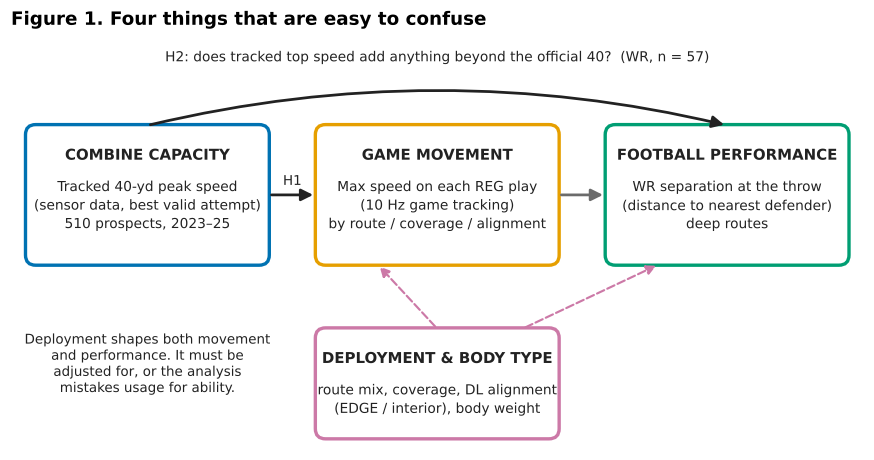

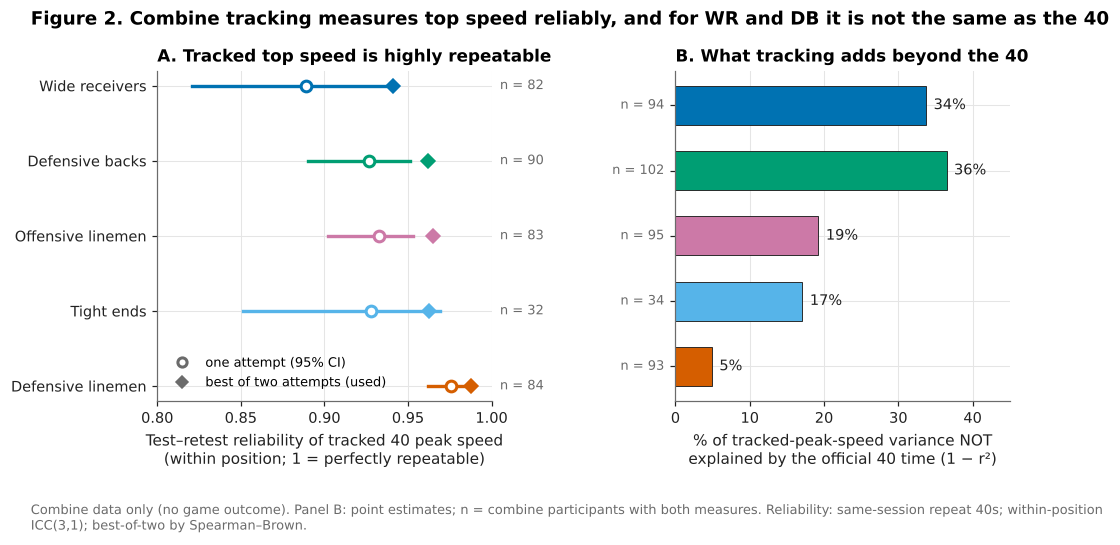

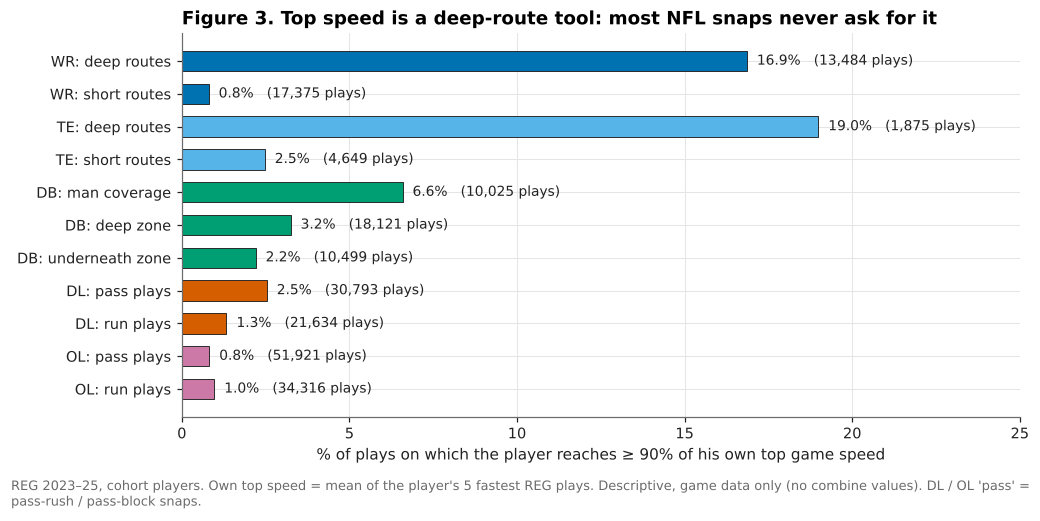

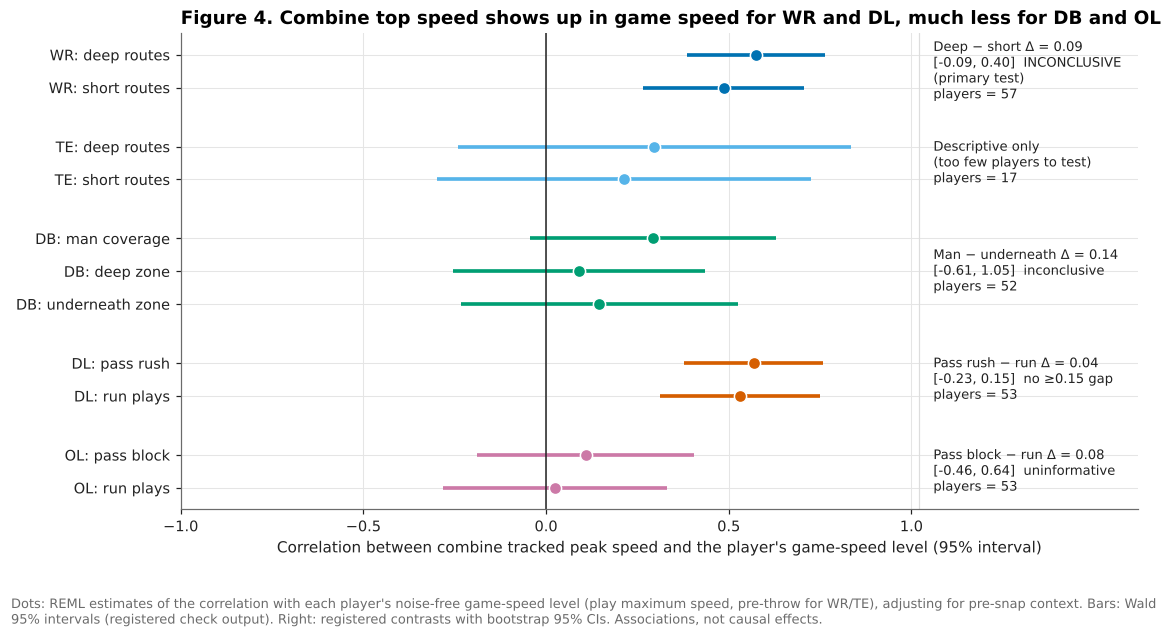

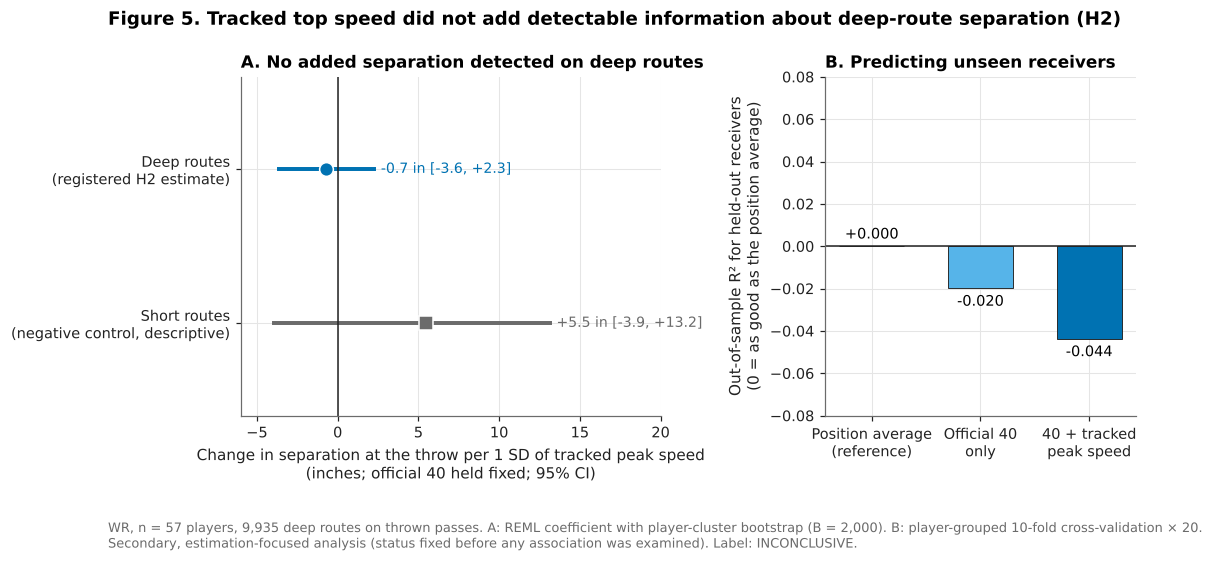

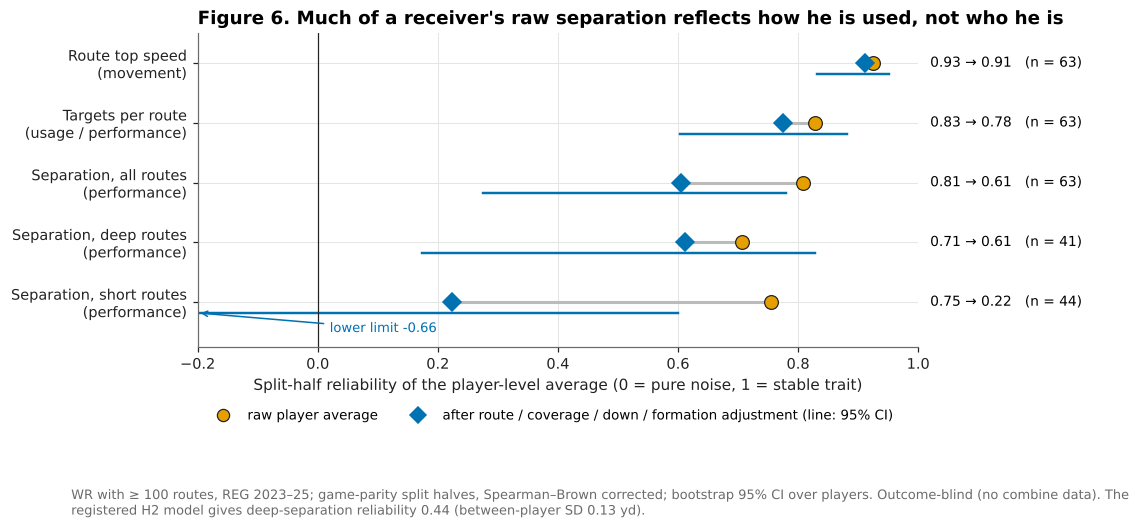

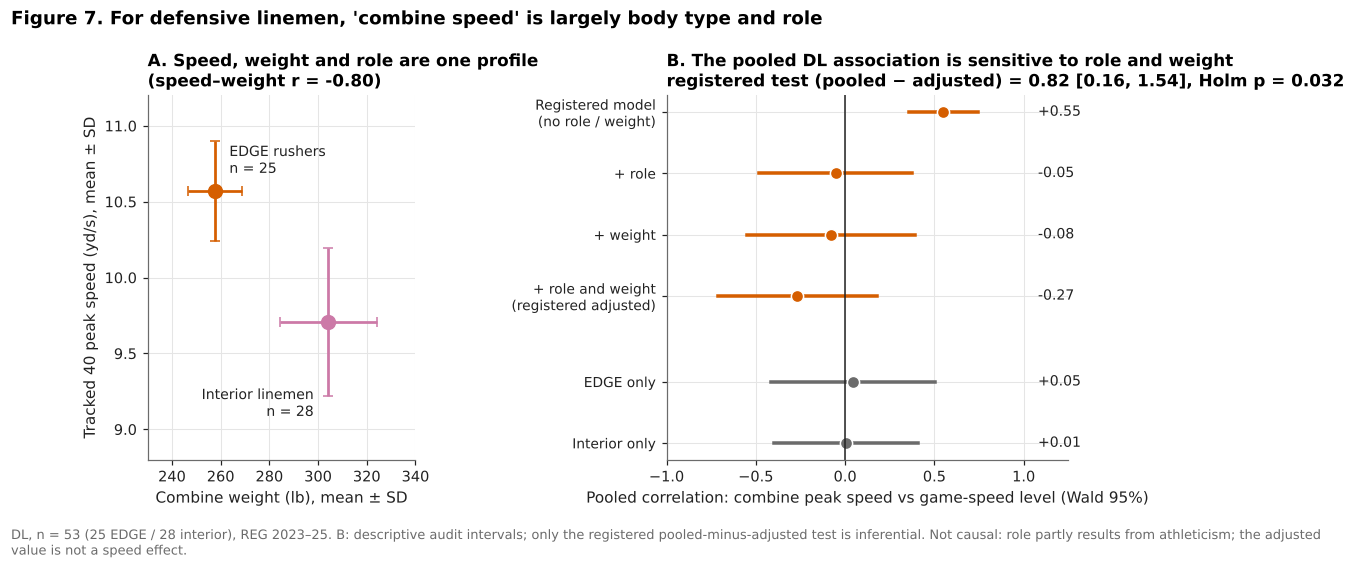

In [10]:
sf.apply_style()
for name, fn in sf.FIGURES.items():
    fig = fn(REGISTERED); plt.show(); plt.close(fig)

## 9. Reproducibility statement

| step | re-executed here? | how verified |
|---|---|---|
| data validation | yes | assertions in §3 |
| Combine feature definitions (tracked 40 peak speed) | yes, frozen functions | valid-player counts and x_peak sums equal the registered predictor table (§4) |
| game features, exclusions, eligibility, sample sizes | yes, frozen functions (counts only) | equal the registered join validation (§5) |
| H1-WR, H2, secondary-family model fits and bootstraps | **no** (one-shot registered runners) | embedded outputs with run ID, commit and seed (§1, §7) |
| figures | yes, from the embedded registered results | identical to the writeup |

**Why the confirmatory fits are not re-run.** Each runner (`scripts/run_h1_wr_confirmatory.py`, `run_h2_estimation.py`, `run_secondary.py`) refuses to run a second time. Silently re-running them would turn a single pre-registered test into a repeatable one.

An auditor can repeat a fit in the project repository on a fresh copy, under a new run ID labelled as a *reproduction*, with approval. That reproduction would be compared with, but never replace, the registered result. The full REML bootstraps (B = 2,000) take roughly 20–60 minutes per family on 4 CPUs.